<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Lab6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Importing Libraries and Loading Dataset


In [23]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

df = pd.read_csv("/content/restaurant_reviews_1000.csv")

display(df.head())
print(df.shape)

,review,sentiment,label
0,I really enjoyed this restaurant; the salad ta...,positive,1
1,I would gladly return because the sandwich was...,positive,1
2,"The meal was pleasant, fresh, and reasonably p...",positive,1
3,I would gladly return because the curry was ou...,positive,1
4,I will not return because the salad was bland ...,negative,0


(1000, 3)


### 3. Data Preprocessing
We will train **Naïve Bayes**, **Logistic Regression**, **Support Vector Machine (SVM)**, and **Random Forest** classifiers, then compare their evaluation metrics.

In [24]:
# Remove missing values
df = df.dropna(subset=['review', 'sentiment', 'label'])

# Remove duplicate reviews
df = df.drop_duplicates(subset=['review'])

# Convert labels to integers
df['label'] = df['label'].astype(int)

# Verify sentiment and label consistency
print(pd.crosstab(df['sentiment'], df['label']))

# Text preprocessing
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['clean_review'] = df['review'].apply(preprocess_text)

print("\nDataset after preprocessing:")
display(df.head())

print("Total unique reviews:", len(df))

label        0    1
sentiment          
negative   314    0
positive     0  324

Dataset after preprocessing:


,review,sentiment,label,clean_review
0,I really enjoyed this restaurant; the salad ta...,positive,1,i really enjoyed this restaurant the salad tas...
1,I would gladly return because the sandwich was...,positive,1,i would gladly return because the sandwich was...
2,"The meal was pleasant, fresh, and reasonably p...",positive,1,the meal was pleasant fresh and reasonably priced
3,I would gladly return because the curry was ou...,positive,1,i would gladly return because the curry was ou...
4,I will not return because the salad was bland ...,negative,0,i will not return because the salad was bland ...


Total unique reviews: 638


### 4. Seperate Input and Output

In [26]:
X = df['clean_review']
y = df['label']

print("Positive reviews:", sum(y == 1))
print("Negative reviews:", sum(y == 0))

Positive reviews: 324
Negative reviews: 314


### 5. Split Dataset



In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 510
Testing samples: 128


### 6. TF-IDF Vectorization

In [27]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (510, 417)
Testing matrix: (128, 417)


### 7. Train the ML Models

In [28]:
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "SVM": LinearSVC(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    trained_models[name] = model

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=['Negative', 'Positive']
    ))


 Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        63
    Positive       1.00      1.00      1.00        65

    accuracy                           1.00       128
   macro avg       1.00      1.00      1.00       128
weighted avg       1.00      1.00      1.00       128


 Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        63
    Positive       1.00      1.00      1.00        65

    accuracy                           1.00       128
   macro avg       1.00      1.00      1.00       128
weighted avg       1.00      1.00      1.00       128


 SVM
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        63
    Positive       1.00      1.00      1.00        65

    accuracy                           1.00       128
   macro avg       1.00      1.00      1.00       128
weighted avg       1.00      1.0

### 8. Comparison Analysis of Models

In [29]:
results_df = pd.DataFrame(results)

print("COMPARATIVE PERFORMANCE ANALYSIS")

display(results_df.round(4))

COMPARATIVE PERFORMANCE ANALYSIS


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0
3,Random Forest,1.0,1.0,1.0,1.0


### 9. Performance Graph Comparison

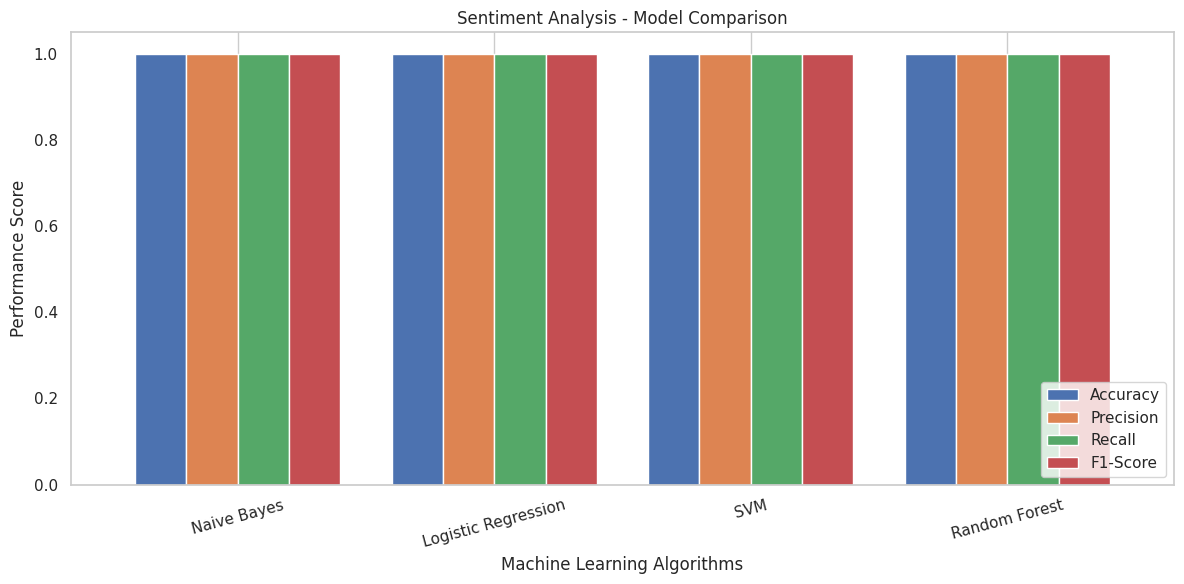

In [30]:
results_df.set_index('Algorithm').plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

plt.title('Sentiment Analysis - Model Comparison')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Performance Score')
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### 10. Confusion Matrix

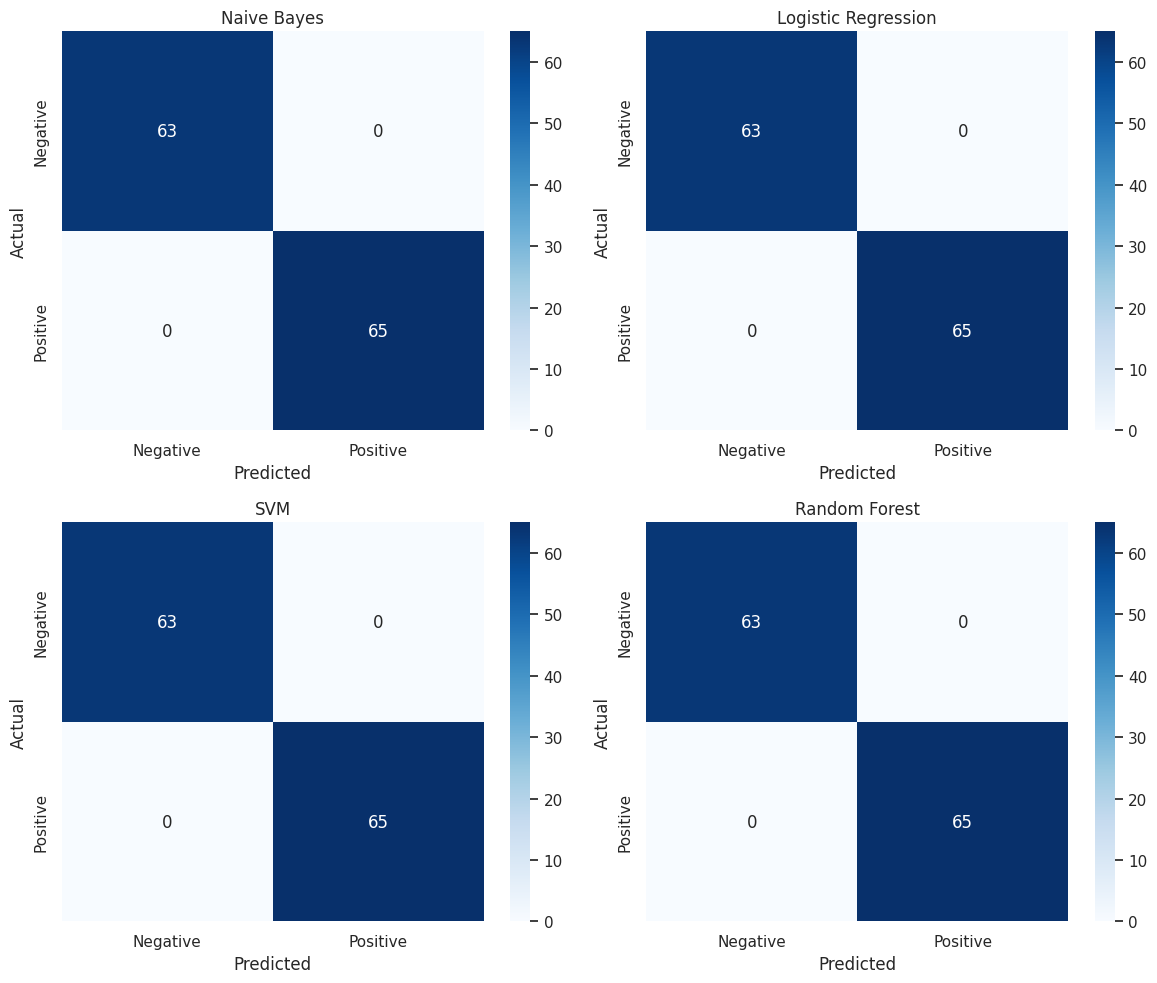

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flatten(), trained_models.items()):

    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 11. Testing Custom Reviews

In [32]:
def predict_sentiment(review):

    cleaned = preprocess_text(review)

    vector = tfidf.transform([cleaned])

    print("\nReview:", review)

    for name, model in trained_models.items():

        prediction = model.predict(vector)[0]

        sentiment = "Positive" if prediction == 1 else "Negative"

        print(name, ":", sentiment)


review = input("Enter a restaurant review: ")

predict_sentiment(review)

Enter a restaurant review: The food was not so great

Review: The food was not so great
Naive Bayes : Negative
Logistic Regression : Negative
SVM : Negative
Random Forest : Negative


In [21]:
# Check duplicate reviews
print("Duplicate reviews:",
      df['review'].duplicated().sum())

# Check class distribution
print(df['sentiment'].value_counts())

# Check unique reviews
print("Total reviews:", len(df))
print("Unique reviews:", df['review'].nunique())

# Check sentiment-label consistency
print(pd.crosstab(df['sentiment'], df['label']))

Duplicate reviews: 0
sentiment
positive    324
negative    314
Name: count, dtype: int64
Total reviews: 638
Unique reviews: 638
label        0    1
sentiment          
negative   314    0
positive     0  324
